In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


### Import target series and detrend series with HP filter lambda=129600

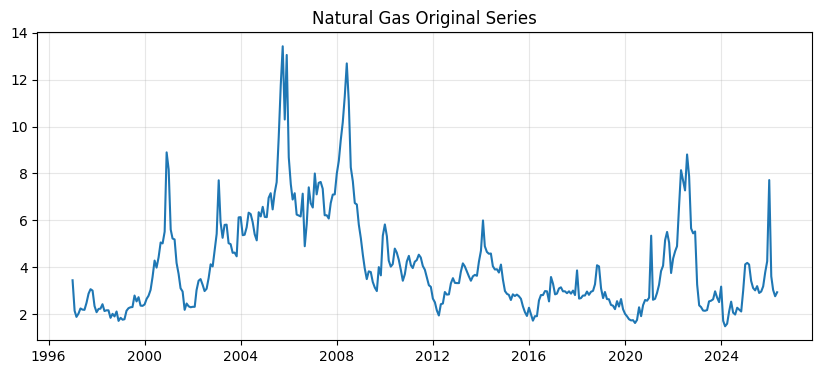

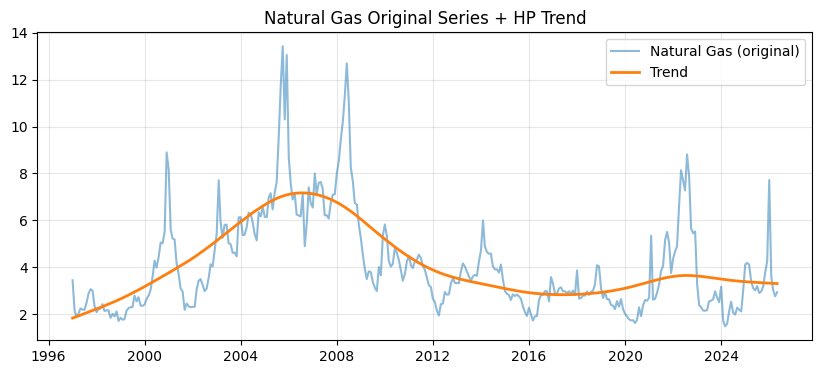

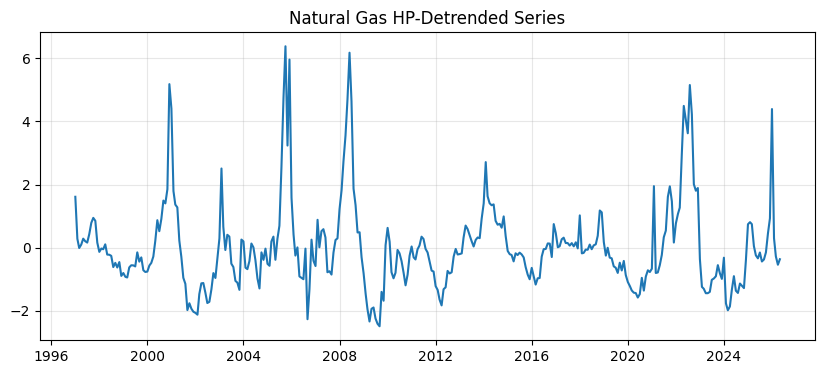

In [2]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()



### Extract Data for Exogeous Variables

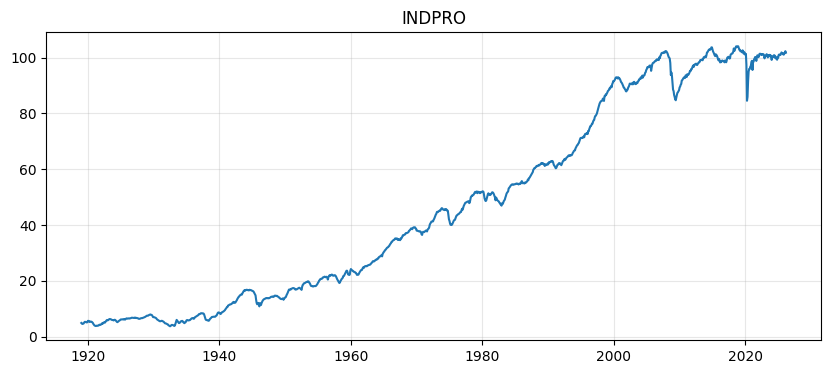

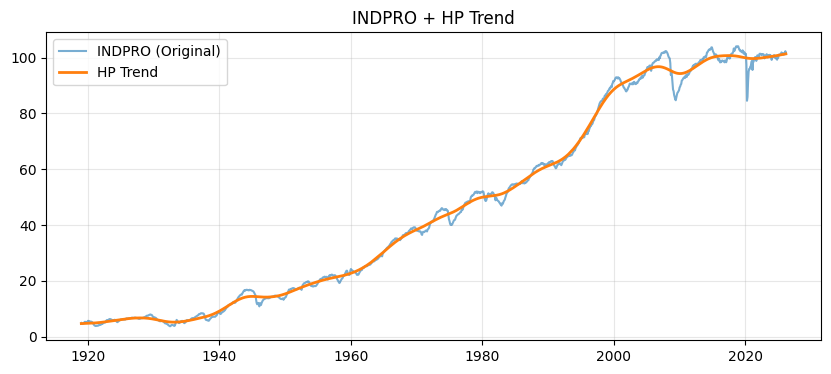

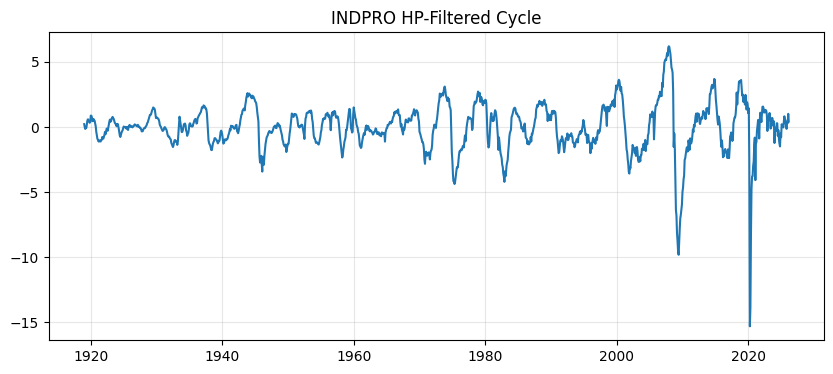

In [3]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")

plt.figure(figsize=(10,4))
plt.plot(indpro_original)
plt.title("INDPRO")
plt.grid(alpha=0.3)
plt.show()

# -------------------------
# HP Filter 
# -------------------------
indpro, trend = hpfilter(indpro_original, lamb=129600)

# -------------------------
# PLOT ORIGINAL + TREND
# -------------------------
plt.figure(figsize=(10,4))
plt.plot(indpro_original, label="INDPRO (Original)", alpha=0.6)
plt.plot(trend, label="HP Trend", linewidth=2)
plt.title("INDPRO + HP Trend")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("INDPRO HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

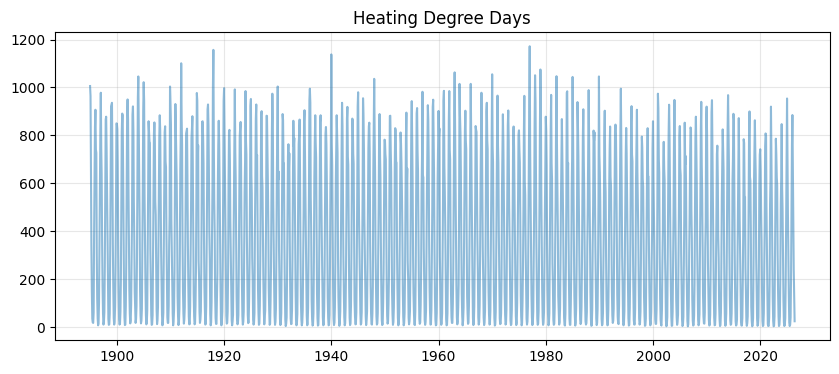

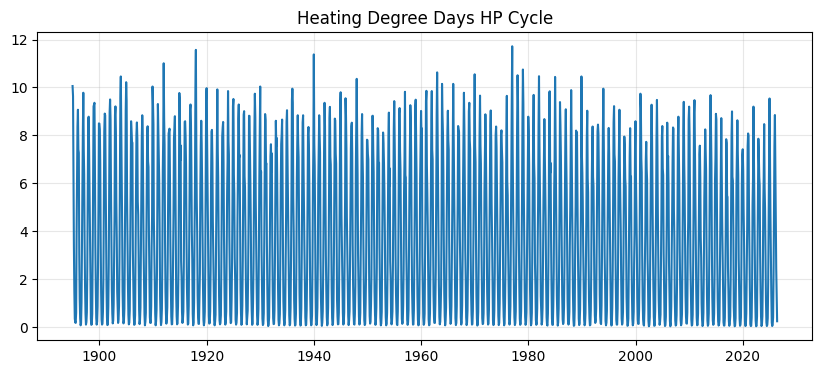

In [4]:
# -------------------------
# Heating Degree Days
# -------------------------
df_hdd = pd.read_csv(
    "HDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_hdd = df_hdd.set_index("Date").dropna()

# HP filter
hdd=0.01*df_hdd

plt.figure(figsize=(10,4))
plt.plot(df_hdd.index, df_hdd["Value"], alpha=0.5)
plt.title("Heating Degree Days")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(df_hdd.index, hdd)
plt.title("Heating Degree Days HP Cycle")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77484/1983831287.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


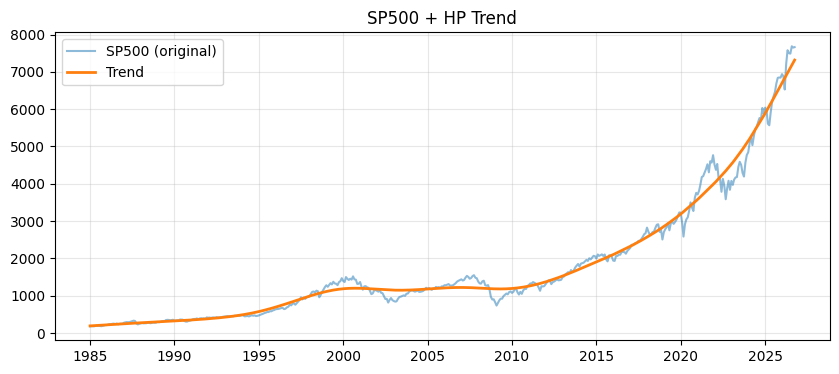

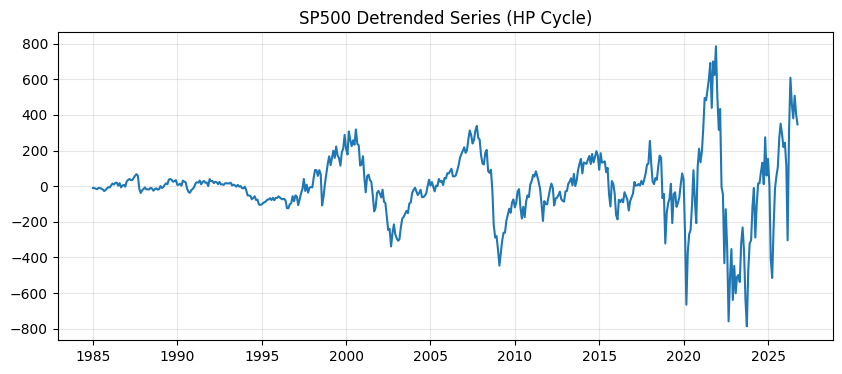

In [5]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500, trend = hpfilter(sp500_original, lamb=129600)


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot( sp500_original, label="SP500 (original)", alpha=0.5)
plt.plot(trend, label="Trend", linewidth=2)
plt.title("SP500 + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 Detrended Series (HP Cycle)")
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_cycle"], indpro, hdd, sp500
    ],
    axis=1
).dropna()

df.columns = ["gas_cycle", "indpro", "hdd", "sp500"]
df = df.sort_index()


start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["gas_cycle"].values
X = df[["indpro", "hdd",  "sp500"]].values

var = ["indpro","hdd", "sp500"]

t0=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")


#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01

y_limits=(-5, 10)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [7]:
# Import PSY Pickle

with open("psy_ngas.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -307.50397841971585

Estimated parameters:
phi             =     0.2456 (0.0255)
psi             =     0.7990 (0.0212)
sigma           =     0.2446 (0.0175)

Hessian condition number:
2.386144304134068

Eigenvalues of Hessian:
[1413.67161501 2489.91716256 3373.22447208]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -307.503978
AIC:            621.007957
BIC:            632.564564
R^2:            0.685517

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 15.200386, p-value = 9.66837e-05
    lag  5: statistic = 28.320955, p-value = 3.15e-05
    lag 10: statistic = 40.439884, p-value = 1.41737e-05
    lag 20: statistic = 46.523054, p-value = 0.000682897

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 24.690583, p-value = 6.73123e-07
    lag  5:

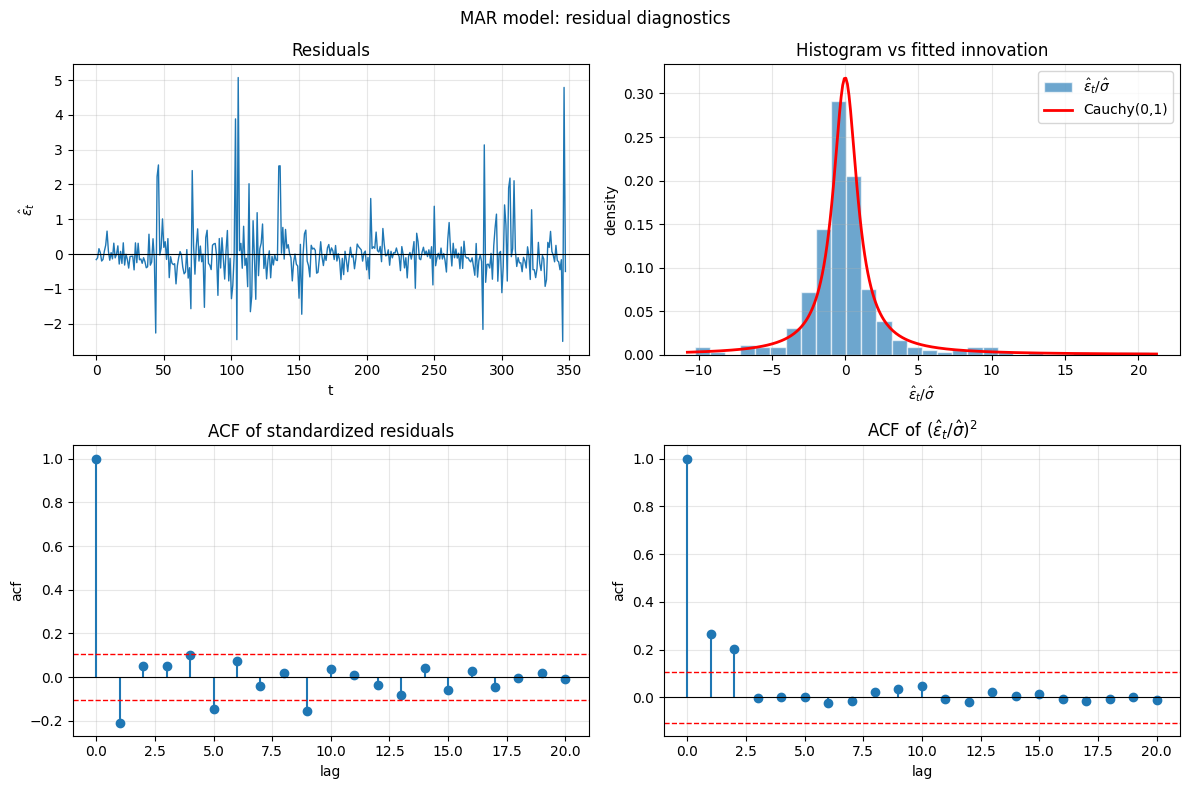

In [8]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

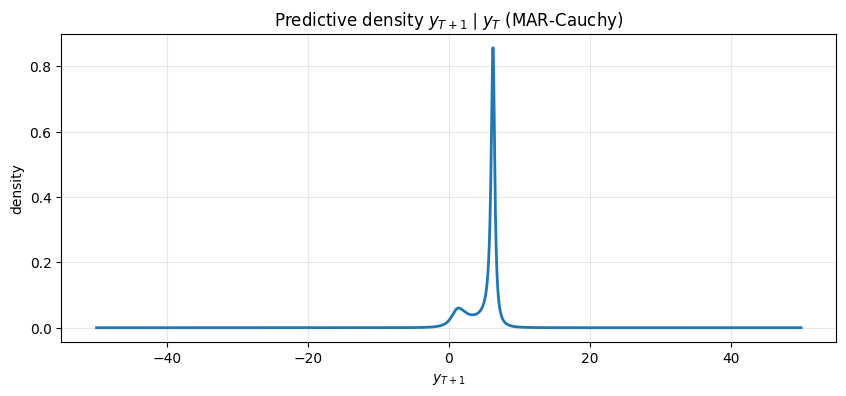

In [9]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

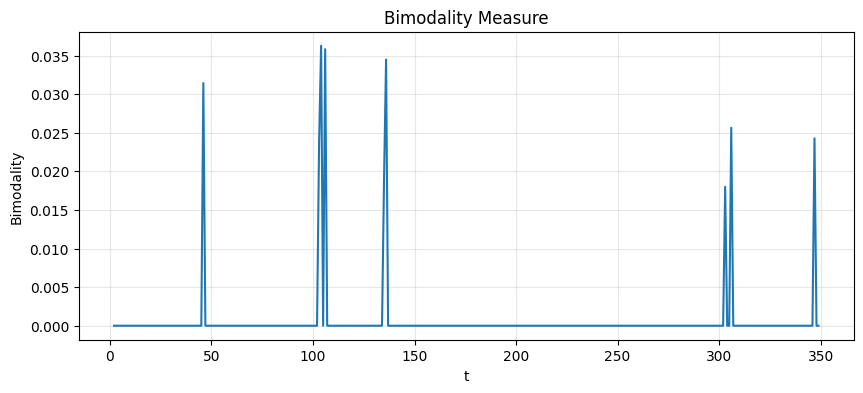

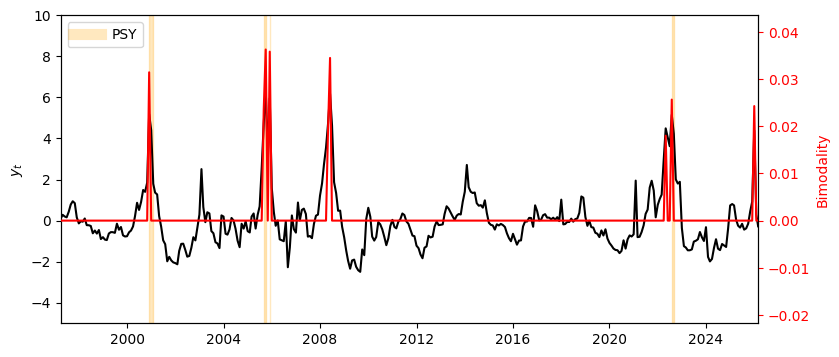

In [10]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -300.6932716793367

Estimated parameters:
phi             =     0.2449 (0.0334)
psi             =     0.7833 (0.0217)
beta_indpro     =     0.0149 (0.0071)
beta_hdd        =    -0.0146 (0.0044)
beta_sp500      =    -0.0002 (0.0001)
sigma           =     0.2353 (0.0172)

Hessian condition number:
111346.45221511697

Eigenvalues of Hessian:
[9.39508895e+07 5.57511257e+04 2.27125816e+04 8.43770839e+02
 2.37664193e+03 3.47796425e+03]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -300.693272
AIC:            613.386543
BIC:            636.499758
R^2:            0.684785

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 13.711162, p-value = 0.000213184
    lag  5: statistic = 26.582502, p-value = 6.87752e-05
    lag 10: statistic = 38.669612, p-value = 2.90025e-05
    lag 20: statistic = 44.301641, p-value = 0.00137103

Autocorrelation tests (s

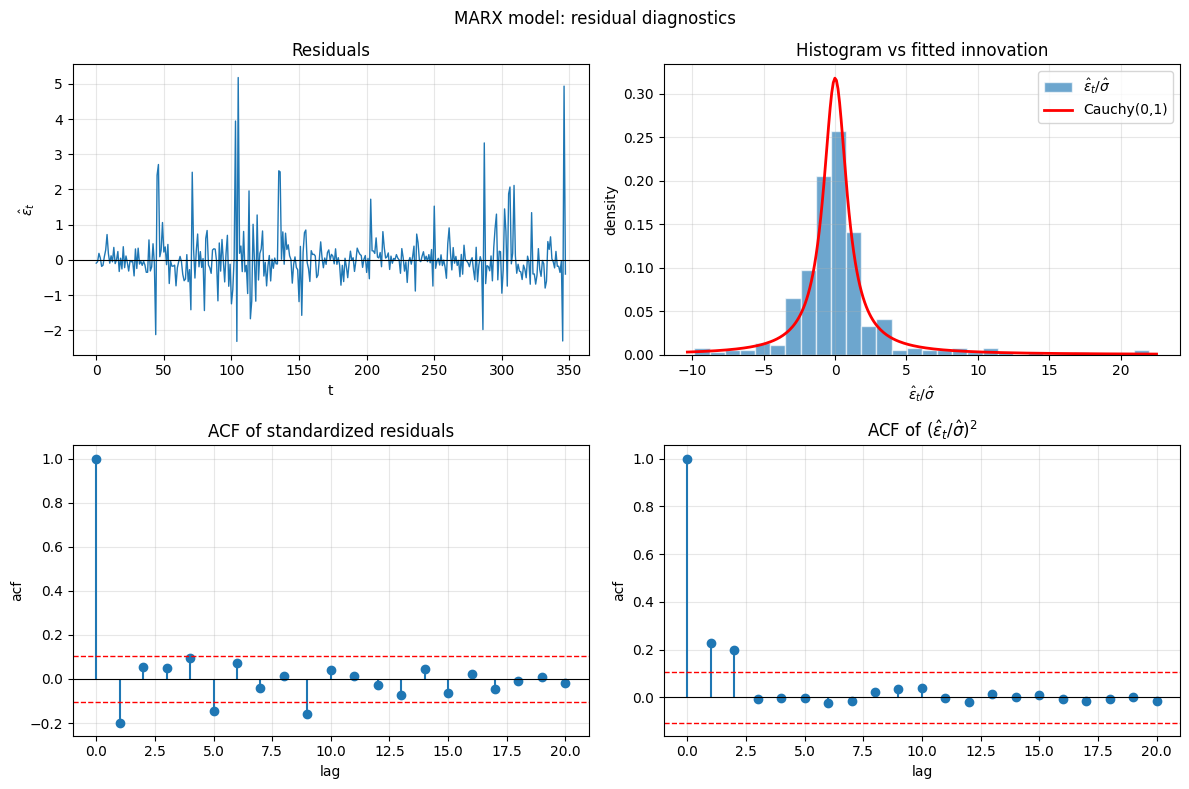

In [11]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_indpro", "beta_hdd", "beta_sp500", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

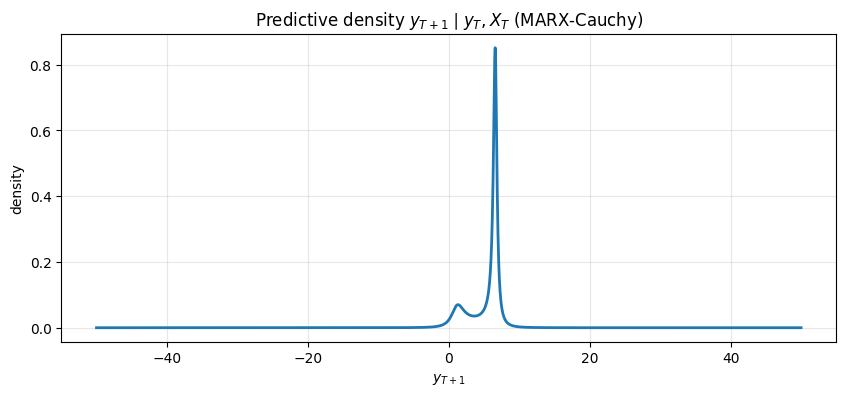

In [12]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

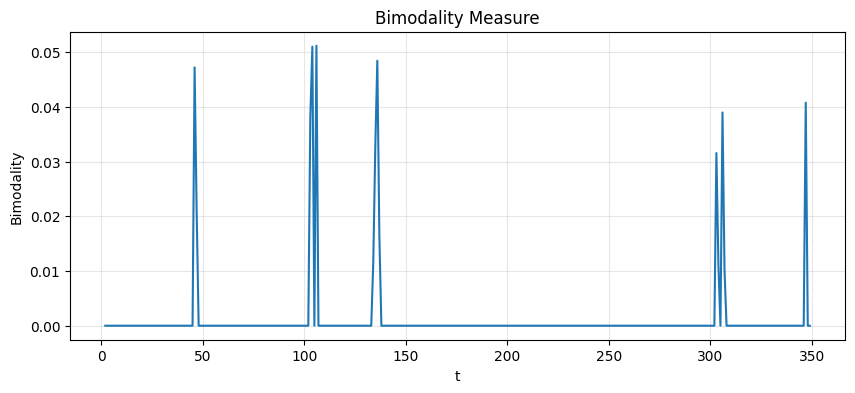

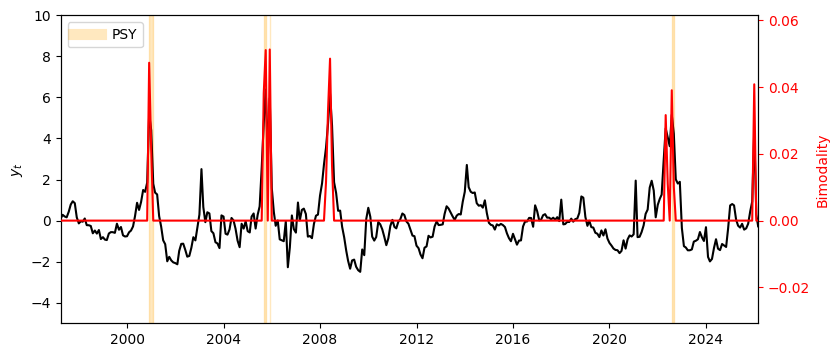

In [13]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

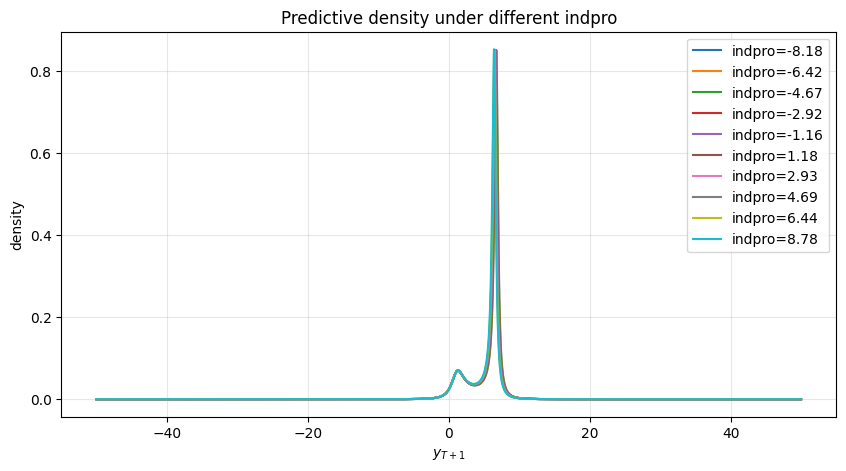

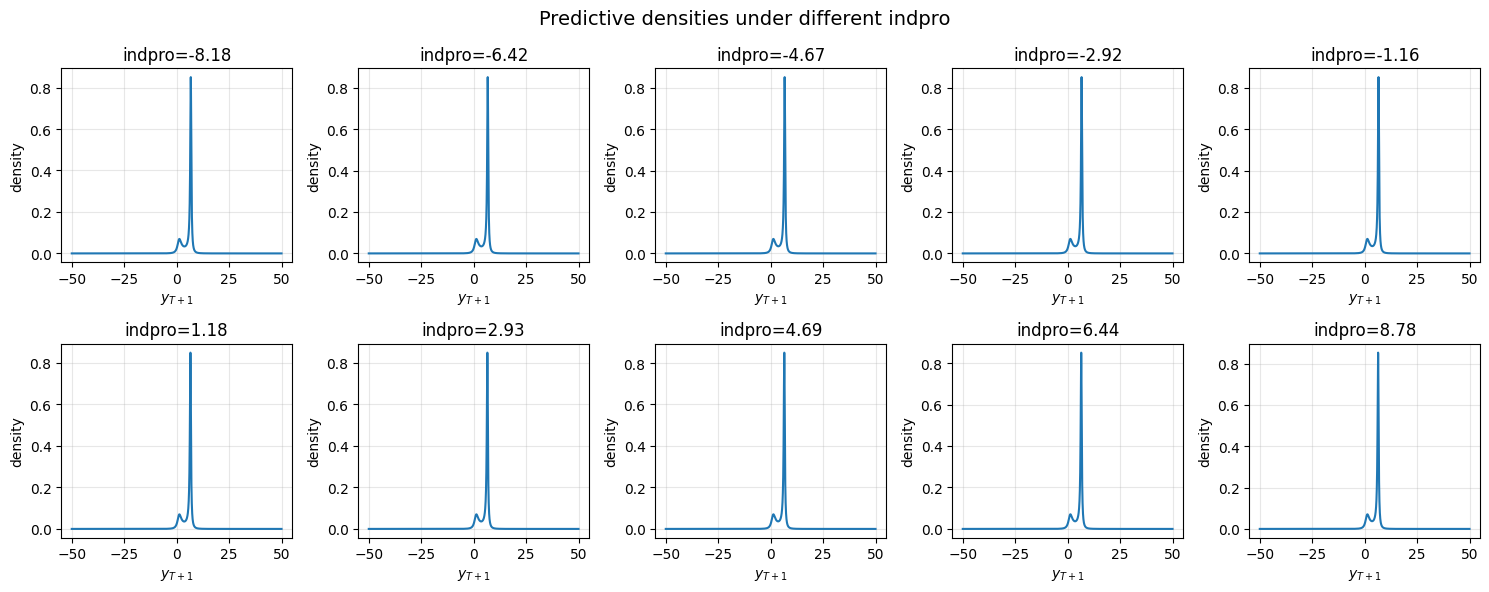

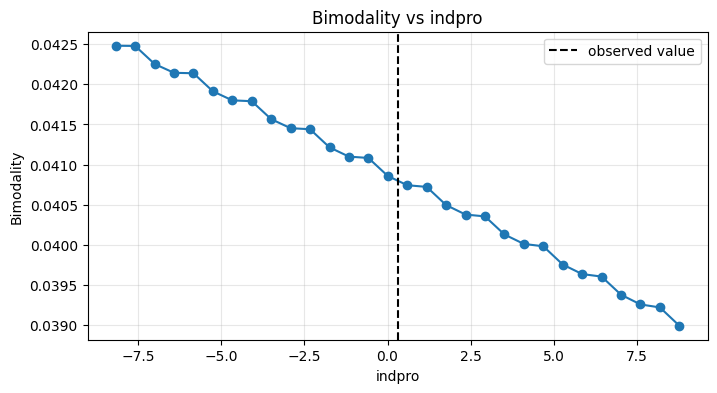

In [14]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -297.64750538020814

Estimated parameters:
phi             =     0.2268 (0.0342)
psi             =     0.7891 (0.0238)
sigma           =     0.3192 (0.0262)
nu              =     2.0100 (0.2989)

Hessian condition number:
244.84165177866606

Eigenvalues of Hessian:
[2729.77431172 2077.1610382   801.92314961   11.14914187]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -297.647505
AIC:            603.295011
BIC:            618.703821
R^2:            0.688482

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 11.504771, p-value = 0.000694178
    lag  5: statistic = 24.744556, p-value = 0.000156081
    lag 10: statistic = 36.542971, p-value = 6.7875e-05
    lag 20: statistic = 42.704844, p-value = 0.00223601

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: st

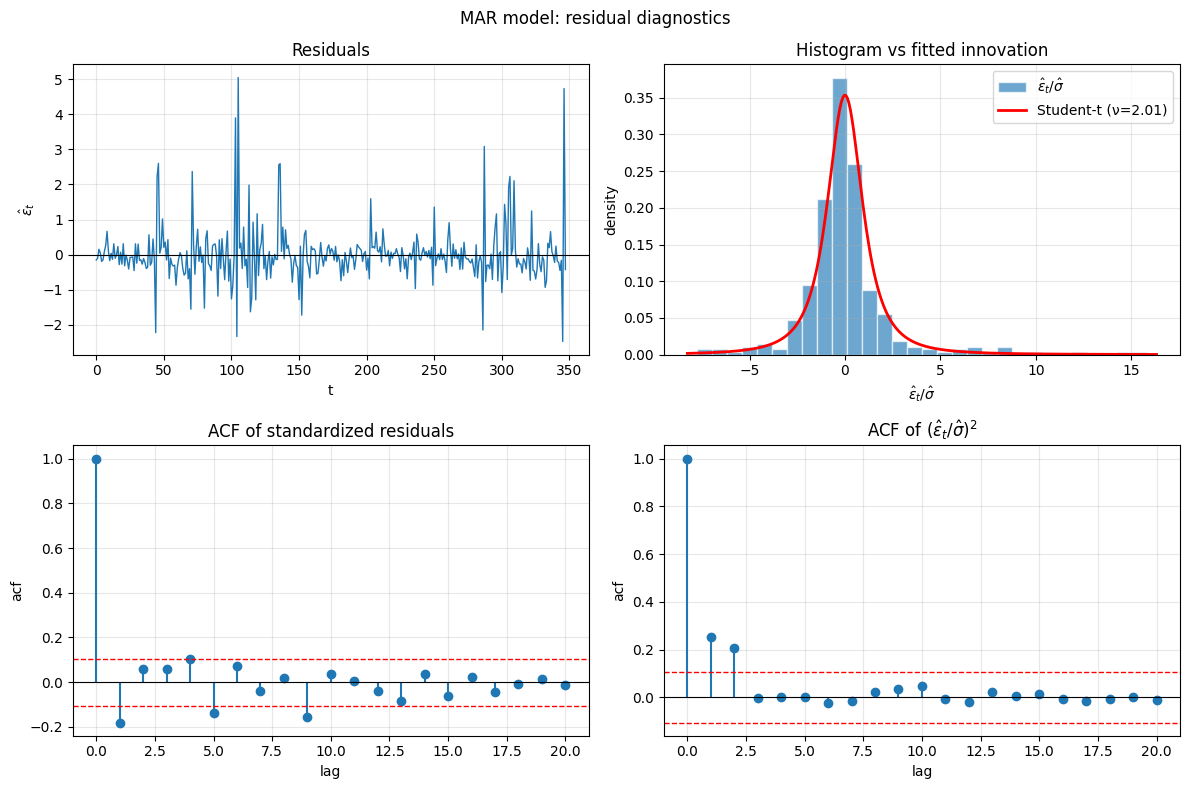

In [17]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

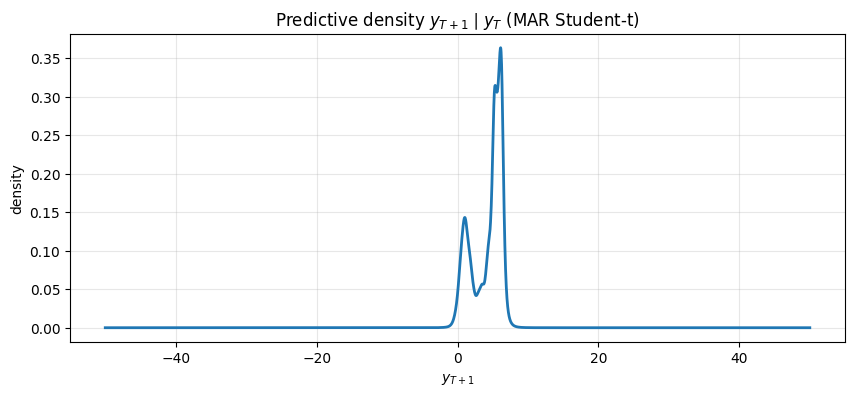

In [18]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

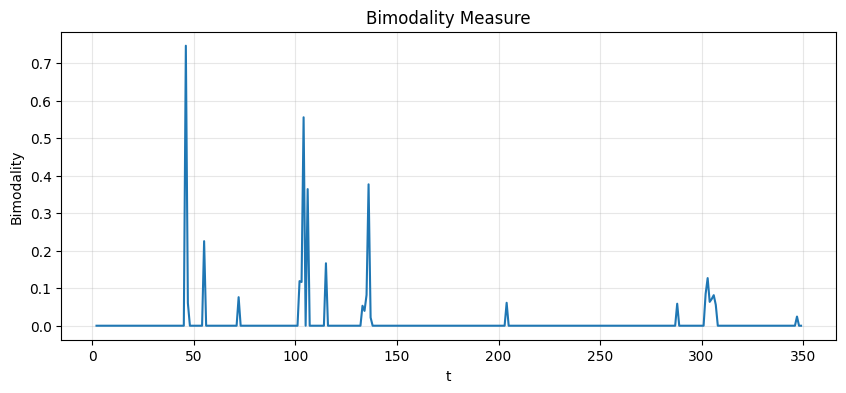

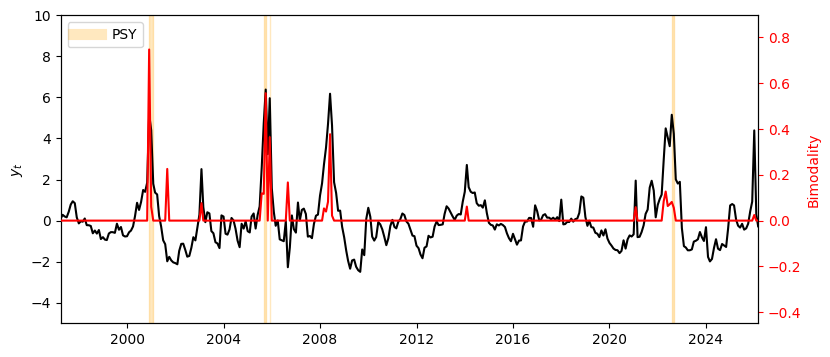

In [19]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -292.354974072241

Estimated parameters:
phi             =     0.2295 (0.0382)
psi             =     0.7664 (0.0280)
beta_indpro     =     0.0190 (0.0088)
beta_hdd        =    -0.0138 (0.0052)
beta_sp500      =    -0.0001 (0.0001)
sigma           =     0.3129 (0.0269)
nu              =     2.0100 (0.3127)

Hessian condition number:
7914254.002818918

Eigenvalues of Hessian:
[8.06033269e+07 4.04150294e+04 1.57154585e+04 2.78241837e+03
 1.69987249e+03 6.07459362e+02 1.01845767e+01]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -292.354974
AIC:            598.709948
BIC:            625.675366
R^2:            0.688618

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 10.167492, p-value = 0.00142939
    lag  5: statistic = 23.284905, p-value = 0.00029775
    lag 10: statistic = 35.102017, p-value = 0.000119957
    lag 20: statistic = 40.94714

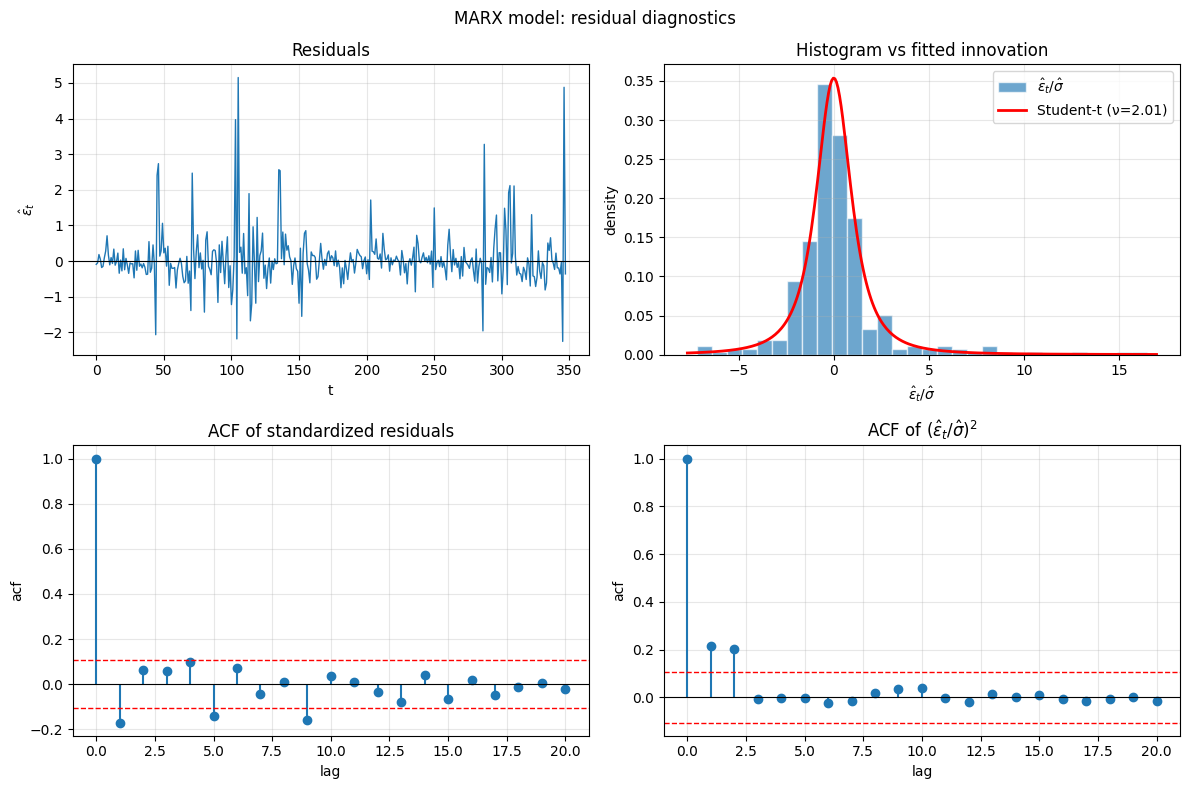

In [20]:
param_names = [ "phi", "psi", "beta_indpro","beta_hdd", "beta_sp500", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

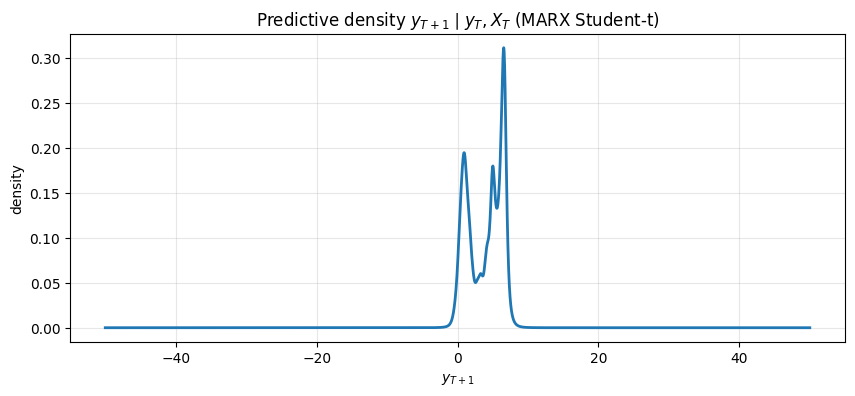

In [21]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

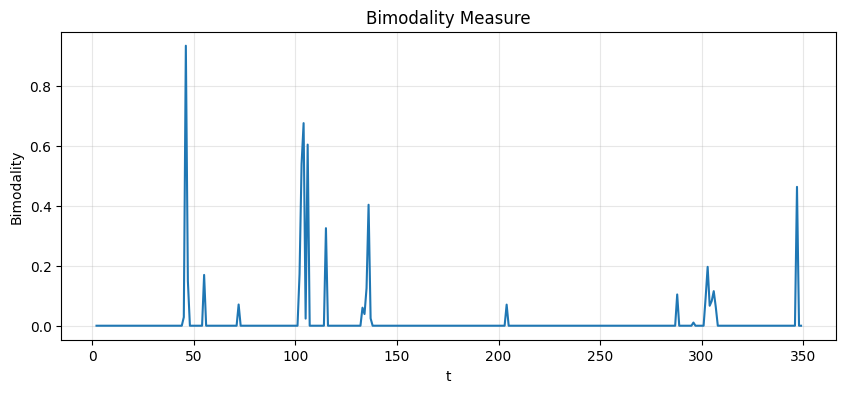

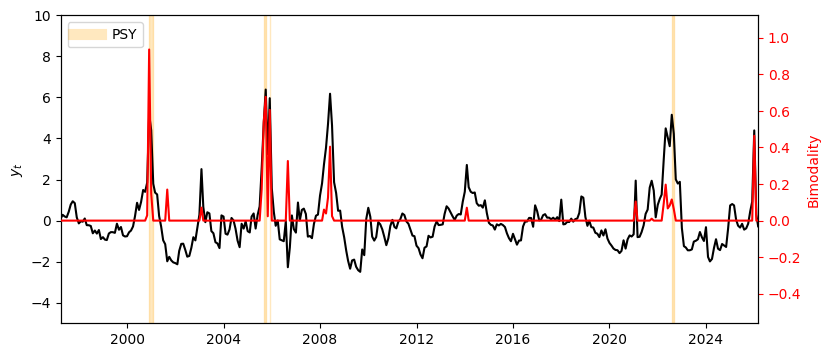

In [22]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

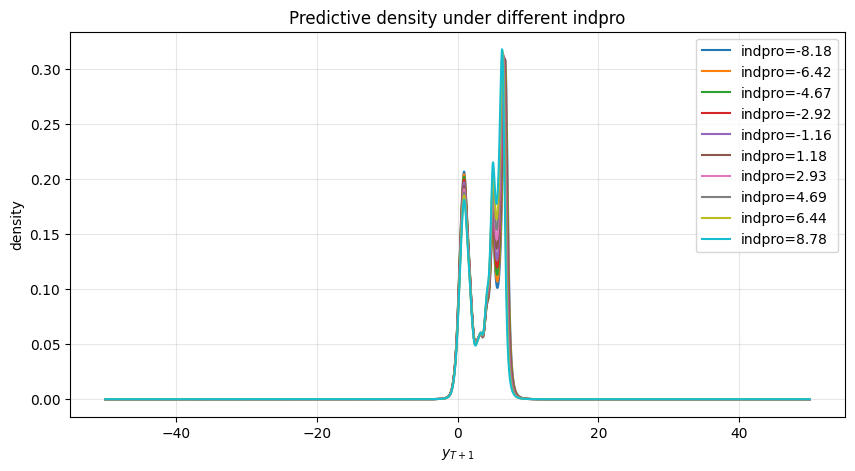

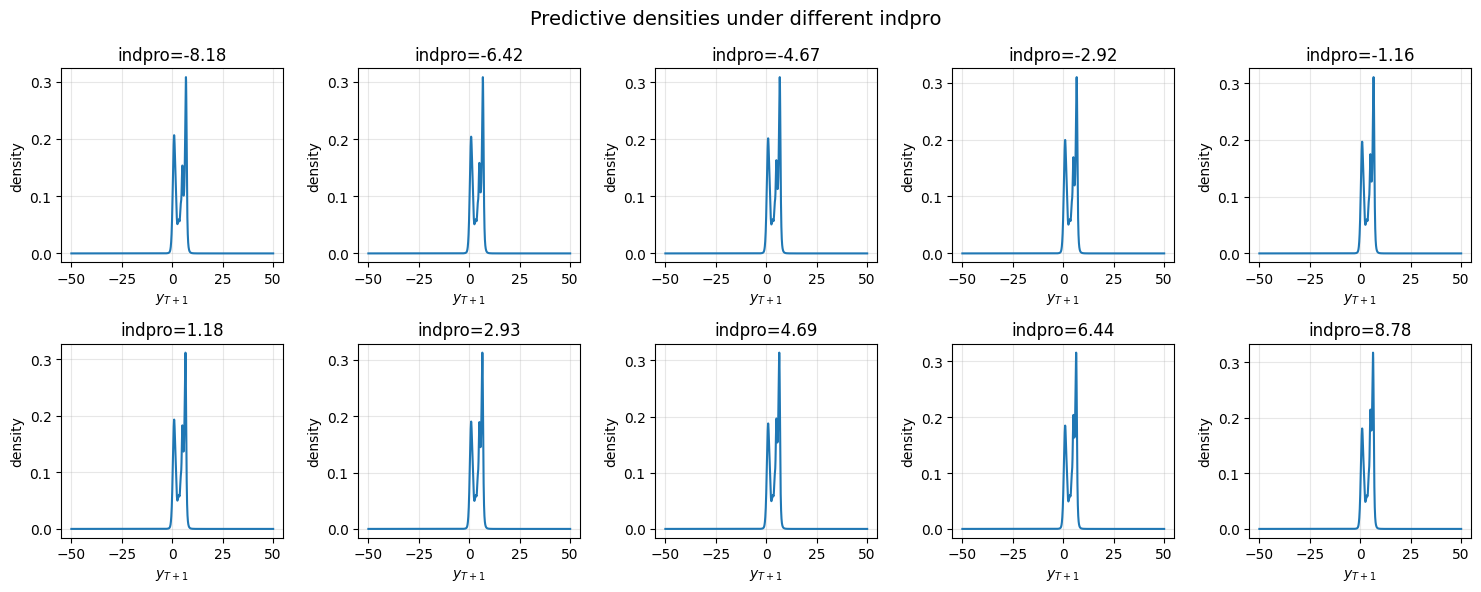

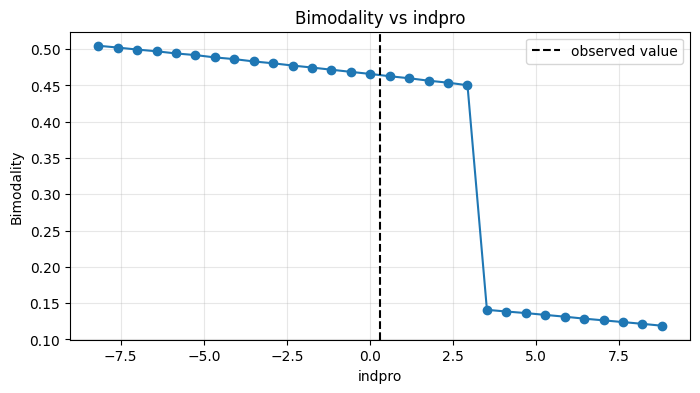

In [23]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)
